# Laboratory Assignment 8: High-Performance Big Data Analytics Using R
## NYC Yellow Taxi Trip Records

**Goal:** Process NYC TLC Yellow Taxi data in R, analyze transportation patterns, compare base R / functional / vectorized / `data.table` approaches, benchmark sequential vs parallel processing, and visualize findings.

Dataset source: official NYC TLC Yellow Taxi Trip Records and Taxi Zone Lookup Table.


## 1. Install and load packages
This notebook uses `data.table`, `arrow`, `lubridate`, `ggplot2`, `purrr`, `foreach`, `doParallel`, and `microbenchmark`. The code installs any missing packages.

In [ ]:
required_packages <- c(
  "data.table", "arrow", "lubridate", "ggplot2",
  "purrr", "foreach", "doParallel", "microbenchmark"
)
missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages)) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}
invisible(lapply(required_packages, library, character.only = TRUE))


## 2. Select and download the data
The official TLC trip records are Parquet files. Three months are selected by default to provide a meaningful dataset without immediately loading a full year. You can adjust the year/months. If a selected monthly file is unavailable, change the period to a month listed on the official TLC page.

In [ ]:
YEAR <- 2025
MONTHS <- c("01", "02", "03")  # e.g. c("01") for a smaller first run

trip_base_url <- "https://d37ci6vzurychx.cloudfront.net/trip-data"
zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

trip_files <- vapply(MONTHS, function(m) {
  url <- sprintf("%s/yellow_tripdata_%d-%s.parquet", trip_base_url, YEAR, m)
  dest <- sprintf("yellow_tripdata_%d-%s.parquet", YEAR, m)
  if (!file.exists(dest)) {
    message("Downloading: ", url)
    download.file(url, dest, mode = "wb", quiet = FALSE)
  }
  dest
}, character(1))

if (!file.exists("taxi_zone_lookup.csv")) {
  download.file(zone_url, "taxi_zone_lookup.csv", mode = "wb", quiet = FALSE)
}

length(trip_files)
file.info(trip_files)[, c("size", "mtime")]


[1] 3

,size,mtime
,<dbl>,<dttm>
yellow_tripdata_2025-01.parquet,59158238,2026-10-10 11:25:02
yellow_tripdata_2025-02.parquet,60343086,2026-10-10 11:25:03
yellow_tripdata_2025-03.parquet,69964745,2026-10-10 11:25:03


## 3. Import, inspect, clean, and prepare data
Only relevant columns are retained to reduce memory use. Invalid timestamps, non-positive distances, and negative fare/total amounts are excluded for the main fare analysis. The number of excluded rows is reported.

In [ ]:
needed_cols <- c(
  "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "passenger_count", "trip_distance", "PULocationID", "DOLocationID",
  "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"
)

trip_list <- lapply(trip_files, function(f) {
  x <- as.data.table(arrow::read_parquet(f, col_select = needed_cols))
  x[, source_month := basename(f)]
  x
})
trips <- rbindlist(trip_list, use.names = TRUE, fill = TRUE)
rm(trip_list)
gc()

cat("Rows and columns before cleaning:", dim(trips), "\\n")
print(str(trips))
print(summary(trips[, .(passenger_count, trip_distance, fare_amount, total_amount)]))
cat("Duplicate rows before cleaning:", sum(duplicated(trips)), "\\n")

before_rows <- nrow(trips)
trips <- unique(trips)
trips[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, tz = "UTC")]
trips[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, tz = "UTC")]

trips <- trips[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  tpep_dropoff_datetime >= tpep_pickup_datetime &
  is.finite(trip_distance) & trip_distance > 0 &
  is.finite(fare_amount) & fare_amount >= 0 &
  is.finite(total_amount) & total_amount >= 0
]
cat("Rows removed by duplicate/validity filtering:", before_rows - nrow(trips), "\\n")
cat("Rows and columns after cleaning:", dim(trips), "\\n")

trips[, `:=`(
  hour = lubridate::hour(tpep_pickup_datetime),
  day = lubridate::day(tpep_pickup_datetime),
  weekday = factor(
    lubridate::wday(tpep_pickup_datetime, label = TRUE, abbr = FALSE, week_start = 1),
    levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")
  ),
  month = lubridate::month(tpep_pickup_datetime, label = TRUE, abbr = TRUE),
  pickup_date = as.Date(tpep_pickup_datetime)
)]


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,1576652,84.3,2861065,152.8,2861065,152.8
Vcells,114842303,876.2,359247528,2740.9,373597414,2850.4


Rows and columns before cleaning: 11198026 12 \nClasses ‘data.table’ and 'data.frame':	11198026 obs. of  12 variables:
 $ tpep_pickup_datetime : POSIXct, format: "2025-01-01 00:18:38" "2025-01-01 00:32:40" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2025-01-01 00:26:59" "2025-01-01 00:35:13" ...
 $ passenger_count      : int  1 1 1 3 3 2 0 0 0 1 ...
 $ trip_distance        : num  1.6 0.5 0.6 0.52 0.66 2.63 0.4 1.6 2.8 1.71 ...
 $ PULocationID         : int  229 236 141 244 244 239 170 234 148 237 ...
 $ DOLocationID         : int  237 237 141 244 116 68 170 148 170 262 ...
 $ payment_type         : int  1 1 1 2 2 2 1 1 1 2 ...
 $ fare_amount          : num  10 5.1 5.1 7.2 5.8 19.1 4.4 12.1 19.1 11.4 ...
 $ tip_amount           : num  3 2.02 2 0 0 0 2.35 2 3 0 ...
 $ tolls_amount         : num  0 0 0 0 0 0 0 0 0 0 ...
 $ total_amount         : num  18 12.1 12.1 9.7 8.3 ...
 $ source_month         : chr  "yellow_tripdata_2025-01.parquet" "yellow_tripdata_2025-01.parquet" "yellow_trip

## 4. Join the Taxi Zone Lookup Table
The lookup table maps pickup/drop-off location IDs to zone and borough names. `data.table` joins are used for efficient integration.

In [ ]:

zones <- fread("taxi_zone_lookup.csv")

# Standardize column names
setnames(zones, tolower(names(zones)))
setnames(zones, old = "locationid", new = "LocationID")

# Convert location IDs to integers
trips[, PULocationID := as.integer(PULocationID)]
trips[, DOLocationID := as.integer(DOLocationID)]

# Create pickup and drop-off lookup tables
pickup_zones <- zones[, .(
  PULocationID = LocationID,
  pickup_borough = borough,
  pickup_zone = zone
)]

dropoff_zones <- zones[, .(
  DOLocationID = LocationID,
  dropoff_borough = borough,
  dropoff_zone = zone
)]

# Join zone information
trips <- merge(
  trips, pickup_zones,
  by = "PULocationID",
  all.x = TRUE,
  sort = FALSE
)

trips <- merge(
  trips, dropoff_zones,
  by = "DOLocationID",
  all.x = TRUE,
  sort = FALSE
)

# Create route labels
trips[, route := paste(
  fifelse(is.na(pickup_zone),
          paste0("ID ", PULocationID), pickup_zone),
  "->",
  fifelse(is.na(dropoff_zone),
          paste0("ID ", DOLocationID), dropoff_zone)
)]

cat("Final rows:", format(nrow(trips), big.mark = ","), "\n")


Final rows: 10,414,893 


## 5. Transportation analytics using `data.table`
The tables below answer the assignment questions on hourly/daily/monthly demand, fare/revenue, routes, distance vs fare, and payment preferences.

In [ ]:
trips_by_hour <- trips[, .(trips = .N), by = hour][order(hour)]
trips_by_weekday <- trips[, .(trips = .N), by = weekday][order(weekday)]
trips_by_month <- trips[, .(trips = .N), by = .(month)][order(month)]
fare_by_hour <- trips[, .(
  trips = .N,
  average_fare = mean(fare_amount, na.rm = TRUE),
  total_revenue = sum(total_amount, na.rm = TRUE)
), by = hour][order(hour)]

top_routes <- trips[, .(trips = .N, revenue = sum(total_amount, na.rm = TRUE)),
                    by = route][order(-trips)][1:15]
top_revenue_routes <- trips[, .(trips = .N, revenue = sum(total_amount, na.rm = TRUE)),
                            by = route][order(-revenue)][1:15]
distance_fare_summary <- trips[, .(
  trips = .N,
  mean_distance = mean(trip_distance, na.rm = TRUE),
  mean_fare = mean(fare_amount, na.rm = TRUE)
), by = .(distance_band = cut(
  trip_distance,
  breaks = c(0, 1, 2, 5, 10, 20, Inf),
  labels = c("0-1", "1-2", "2-5", "5-10", "10-20", "20+"),
  include.lowest = TRUE
))][order(distance_band)]

payment_summary <- trips[, .(
  trips = .N,
  revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_borough, payment_type)][order(pickup_borough, -trips)]

cat("Trips by hour\\n"); print(trips_by_hour)
cat("Trips by weekday\\n"); print(trips_by_weekday)
cat("Trips by month\\n"); print(trips_by_month)
cat("Fare and revenue by hour\\n"); print(fare_by_hour)
cat("Most frequent routes\\n"); print(top_routes)
cat("Highest-revenue routes\\n"); print(top_revenue_routes)
cat("Distance bands and fares\\n"); print(distance_fare_summary)
cat("Payment methods by pickup borough\\n"); print(payment_summary)


Trips by hour\n     hour  trips
    <int>  <int>
 1:     0 311214
 2:     1 206951
 3:     2 133014
 4:     3  92523
 5:     4  69170
 6:     5  73130
 7:     6 150516
 8:     7 297833
 9:     8 414046
10:     9 431203
11:    10 444972
12:    11 476257
13:    12 519376
14:    13 547809
15:    14 588253
16:    15 617930
17:    16 617414
18:    17 697201
19:    18 741175
20:    19 661630
21:    20 639757
22:    21 649284
23:    22 589046
24:    23 445189
     hour  trips
    <int>  <int>
Trips by weekday\n     weekday   trips
       <ord>   <int>
1:    Monday 1233385
2:   Tuesday 1334742
3: Wednesday 1515622
4:  Thursday 1636818
5:    Friday 1581027
6:  Saturday 1715935
7:    Sunday 1397364
Trips by month\n   month   trips
   <ord>   <int>
1:   Jan 3254347
2:   Feb 3311309
3:   Mar 3849213
4:   Apr       2
5:   Dec      22
Fare and revenue by hour\n     hour  trips average_fare total_revenue
    <int>  <int>        <num>         <num>
 1:     0 311214     19.20791       8545420
 2:     1

## 6. Functional, vectorized, and `data.table` implementations
This section compares equivalent hourly trip-count calculations. `apply()` is demonstrated on a small summary matrix, `lapply()` and `purrr::map()` process groups, and vectorized / `data.table` implementations provide alternatives. Benchmark timings are measured on the actual runtime.

In [ ]:
# Common result for comparisons
hour_counts_dt <- function(d) d[, .(trips = .N), by = hour][order(hour)]

# Base R aggregation
hour_counts_base <- function(d) {
  out <- as.data.frame(table(d$hour), stringsAsFactors = FALSE)
  names(out) <- c("hour", "trips")
  out$hour <- as.integer(as.character(out$hour))
  out$trips <- as.integer(out$trips)
  out[order(out$hour), ]
}

# Vectorized tabulation
hour_counts_vectorized <- function(d) {
  counts <- tabulate(d$hour + 1L, nbins = 24L)
  data.frame(hour = 0:23, trips = counts)
}

# lapply over hours, then combine
hour_counts_lapply <- function(d) {
  pieces <- lapply(0:23, function(h) {
    data.frame(hour = h, trips = sum(d$hour == h, na.rm = TRUE))
  })
  do.call(rbind, pieces)
}

# purrr::map over hours
hour_counts_map <- function(d) {
  purrr::map_dfr(0:23, function(h) {
    data.frame(hour = h, trips = sum(d$hour == h, na.rm = TRUE))
  })
}

# apply() example: apply across numeric summary columns
numeric_summary <- as.matrix(trips[, .(
  trip_distance = mean(trip_distance, na.rm = TRUE),
  fare_amount = mean(fare_amount, na.rm = TRUE),
  total_amount = mean(total_amount, na.rm = TRUE)
)])
apply(numeric_summary, 2, identity)

# Check results agree before benchmarking
print(head(hour_counts_base(trips)))
print(head(hour_counts_vectorized(trips)))
print(head(hour_counts_lapply(trips)))
print(head(hour_counts_map(trips)))
print(head(hour_counts_dt(trips)))
stopifnot(
  identical(hour_counts_vectorized(trips)$trips, hour_counts_dt(trips)$trips),
  identical(hour_counts_lapply(trips)$trips, hour_counts_dt(trips)$trips),
  identical(hour_counts_map(trips)$trips, hour_counts_dt(trips)$trips)
)


trip_distance   fare_amount  total_amount 
     5.824803     18.518110     27.253484

  hour  trips
1    0 311214
2    1 206951
3    2 133014
4    3  92523
5    4  69170
6    5  73130
  hour  trips
1    0 311214
2    1 206951
3    2 133014
4    3  92523
5    4  69170
6    5  73130
  hour  trips
1    0 311214
2    1 206951
3    2 133014
4    3  92523
5    4  69170
6    5  73130
  hour  trips
1    0 311214
2    1 206951
3    2 133014
4    3  92523
5    4  69170
6    5  73130
    hour  trips
   <int>  <int>
1:     0 311214
2:     1 206951
3:     2 133014
4:     3  92523
5:     4  69170
6:     5  73130


In [ ]:
# Benchmark on a configurable sample so repeated timings are practical.
# Set BENCH_N <- nrow(trips) to benchmark the entire dataset if memory/time permit.
BENCH_N <- min(nrow(trips), 300000L)
set.seed(42)
bench_data <- trips[sample.int(nrow(trips), BENCH_N)]

benchmark_results <- microbenchmark::microbenchmark(
  base_R = hour_counts_base(bench_data),
  vectorized = hour_counts_vectorized(bench_data),
  lapply = hour_counts_lapply(bench_data),
  purrr_map = hour_counts_map(bench_data),
  data_table = hour_counts_dt(bench_data),
  times = 5L
)
print(benchmark_results)
benchmark_summary <- as.data.table(summary(benchmark_results))[
  , .(implementation = expr, min_ms = min / 1e6, median_ms = median / 1e6,
      mean_ms = mean / 1e6)
][order(median_ms)]
print(benchmark_summary)


Unit: milliseconds
       expr       min        lq      mean    median        uq       max neval
     base_R 10.208546 16.219071 20.484975 24.515480 25.120482 26.361296     5
 vectorized  1.037327  1.049940  1.632684  1.098480  2.434291  2.543381     5
     lapply 25.421931 25.428843 38.861157 25.471654 58.878895 59.104461     5
  purrr_map 25.308549 25.473061 43.958835 48.613828 59.934911 60.463826     5
 data_table  5.621407  5.745234  7.065316  5.887061  6.171160 11.901716     5
   implementation       min_ms    median_ms      mean_ms
           <fctr>        <num>        <num>        <num>
1:     vectorized 1.037327e-06 1.098480e-06 1.632684e-06
2:     data_table 5.621407e-06 5.887061e-06 7.065316e-06
3:         base_R 1.020855e-05 2.451548e-05 2.048497e-05
4:         lapply 2.542193e-05 2.547165e-05 3.886116e-05
5:      purrr_map 2.530855e-05 4.861383e-05 4.395883e-05


## 7. Sequential vs parallel processing
The operation is the same in both cases: count trips by pickup hour for each month partition. Parallel processing has setup/serialization overhead, so it may not be faster for a small dataset. The speedup is calculated from measured times.

In [ ]:
# Split by source month; each partition has already been loaded.
partitions <- split(trips, trips$source_month)

summarize_partition <- function(d) {
  d[, .(trips = .N), by = hour][order(hour)]
}

seq_time <- system.time({
  sequential_results <- lapply(partitions, summarize_partition)
})

available_cores <- parallel::detectCores(logical = TRUE)
workers <- max(1L, min(2L, available_cores - 1L))
cl <- parallel::makeCluster(workers)
doParallel::registerDoParallel(cl)

par_time <- system.time({
  parallel_results <- foreach::foreach(
    i = seq_along(partitions),
    .packages = "data.table",
    .combine = "c"
  ) %dopar% {
    summarize_partition(partitions[[i]])
  }
})

parallel::stopCluster(cl)
foreach::registerDoSEQ()

seq_seconds <- unname(seq_time[["elapsed"]])
par_seconds <- unname(par_time[["elapsed"]])
speedup <- if (par_seconds > 0) seq_seconds / par_seconds else NA_real_

parallel_comparison <- data.frame(
  method = c("Sequential lapply", "Parallel foreach/doParallel"),
  elapsed_seconds = c(seq_seconds, par_seconds),
  workers = c(1L, workers)
)
print(parallel_comparison)
cat("Speedup (sequential / parallel):", round(speedup, 3), "\\n")


                       method elapsed_seconds workers
1           Sequential lapply           0.239       1
2 Parallel foreach/doParallel          24.060       1
Speedup (sequential / parallel): 0.01 \n

## 8. Additional profiling and memory estimate
`object.size()` gives an approximate in-memory size for the main table. `system.time()` profiles a representative aggregation. These are runtime-specific measurements, not universal performance guarantees.

In [ ]:
cat("Approximate trips object size (MiB):",
    round(as.numeric(object.size(trips)) / 1024^2, 2), "\\n")

profile_time <- system.time({
  revenue_by_borough <- trips[, .(
    trips = .N,
    revenue = sum(total_amount, na.rm = TRUE),
    mean_fare = mean(fare_amount, na.rm = TRUE)
  ), by = pickup_borough][order(-revenue)]
})
print(profile_time)
print(revenue_by_borough)


Approximate trips object size (MiB): 1434.09 \n   user  system elapsed 
  0.446   0.229   0.675 
   pickup_borough   trips      revenue mean_fare
           <char>   <int>        <num>     <num>
1:      Manhattan 9194354 213622952.67  15.17615
2:         Queens  878055  59828163.00  50.31025
3:       Brooklyn  255114   7591791.76  26.58506
4:          Bronx   62943   1985692.82  28.53161
5:        Unknown   21764    627638.88  19.41478
6:            N/A    1667    132603.79  67.36709
7:  Staten Island     782     33563.59  32.08665
8:            EWR     214     19712.64  75.18748


## 9. Visualizations with `ggplot2`
Each plot has a title and axis labels. Use the printed tables and plots to write interpretations based on your own results.

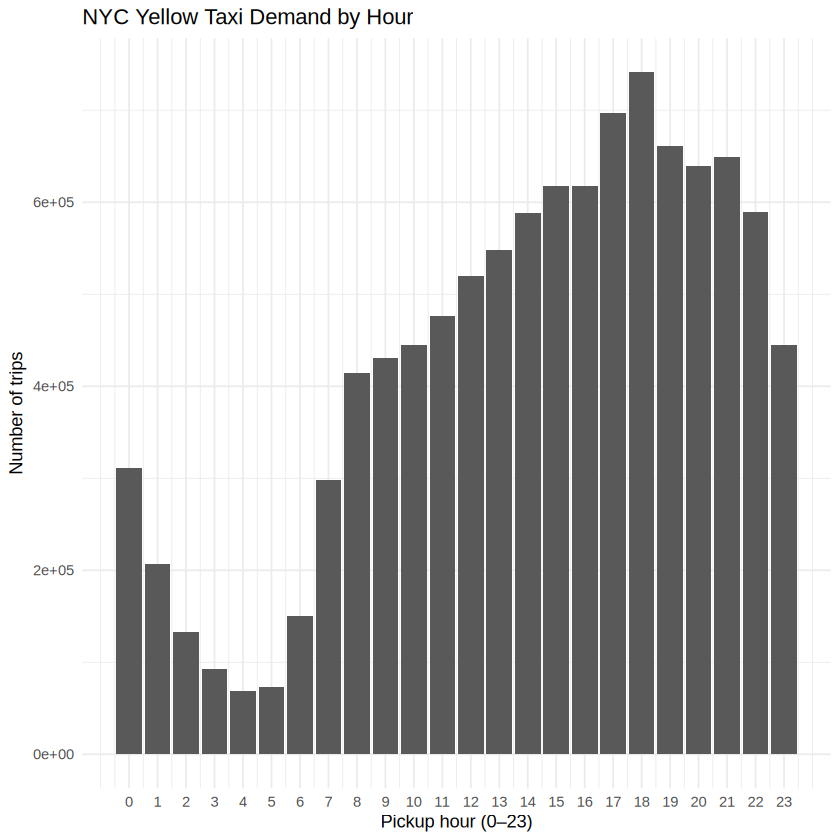

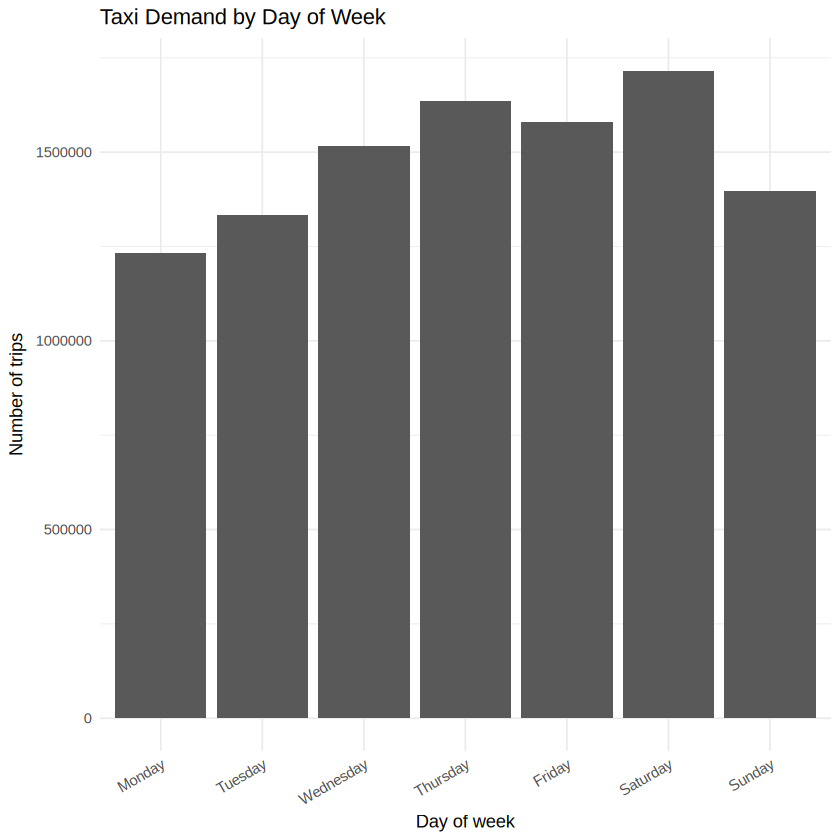

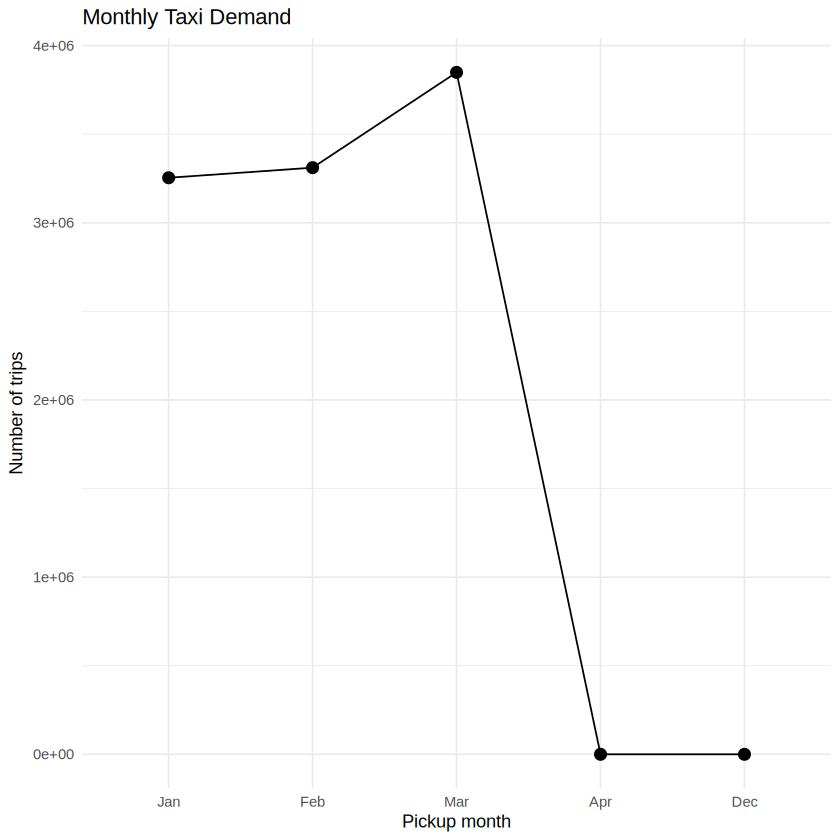

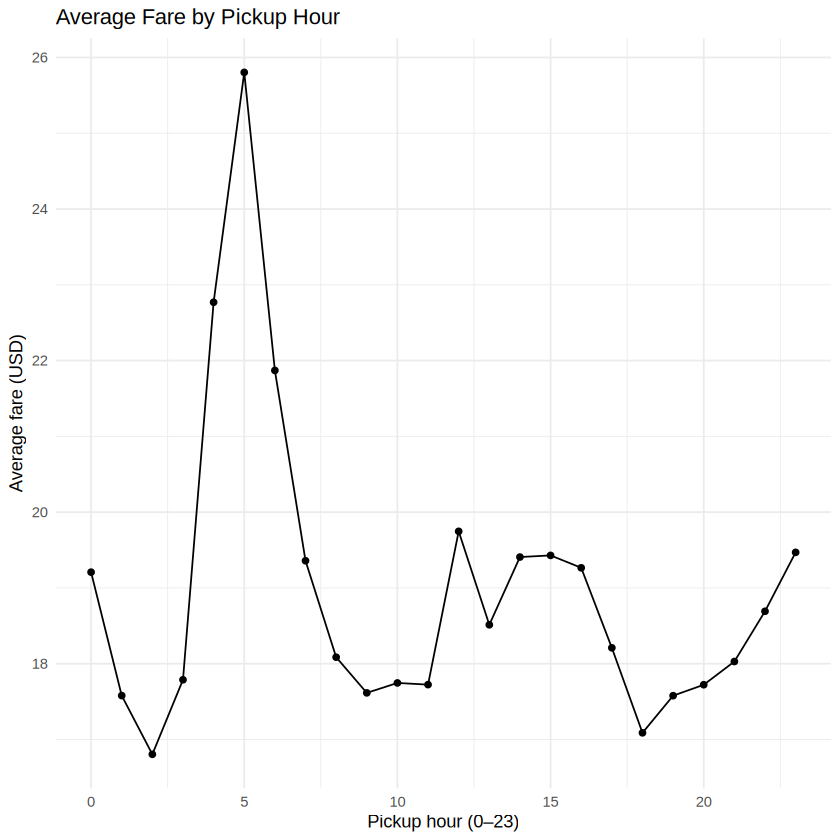

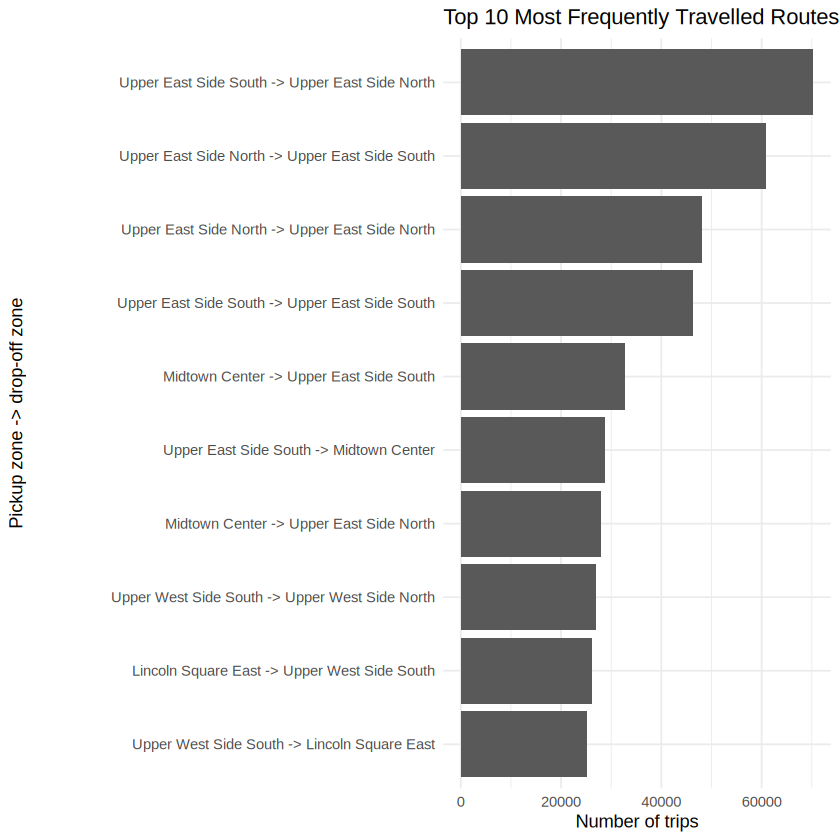

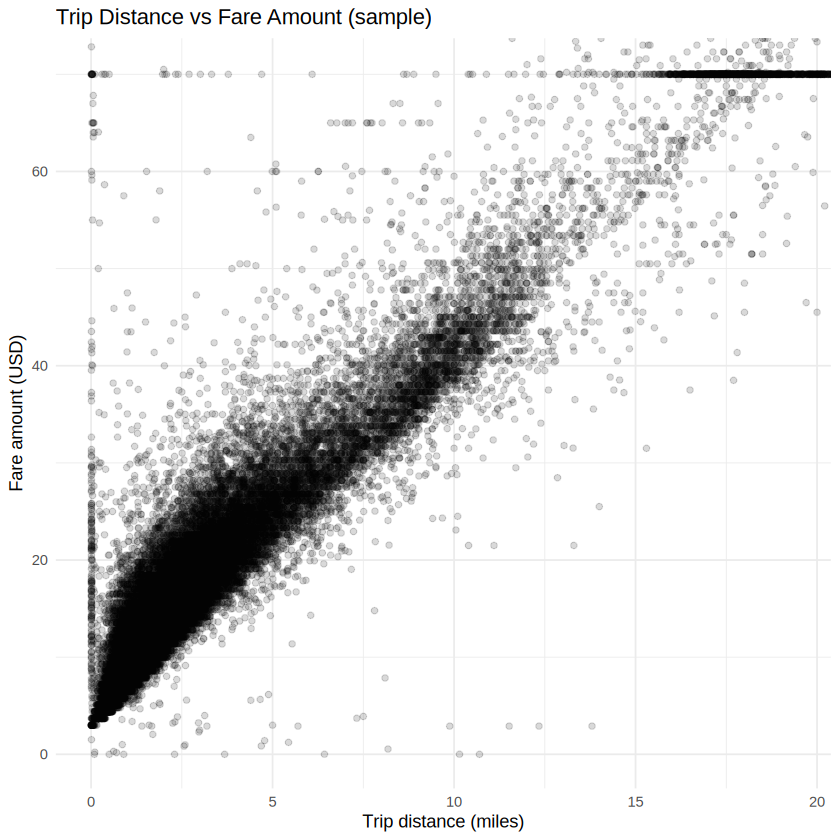

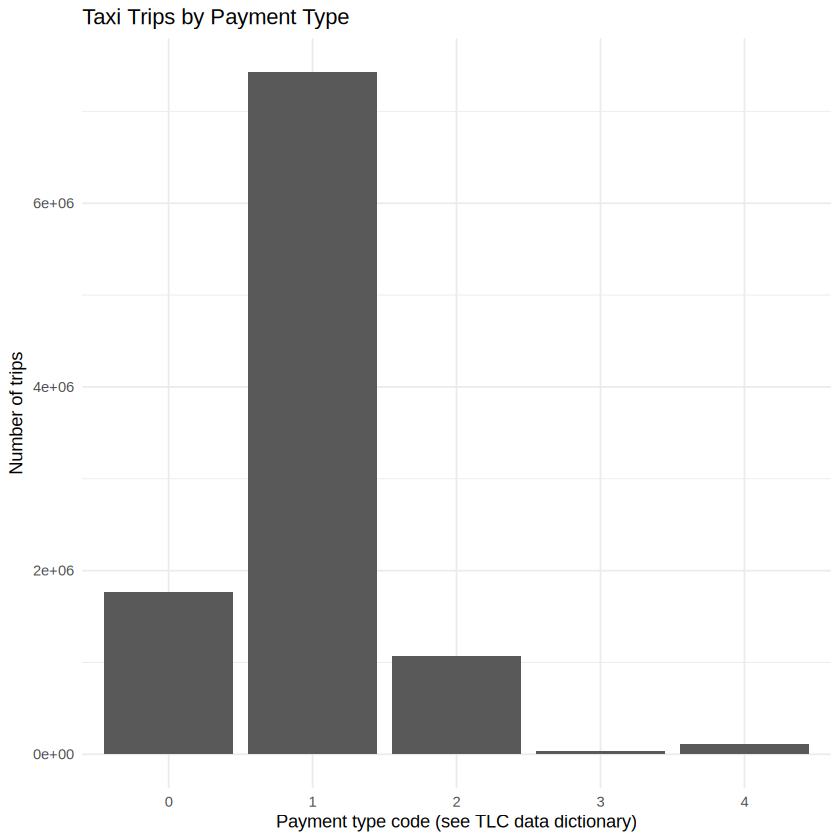

In [ ]:
ggplot(trips_by_hour, aes(x = hour, y = trips)) +
  geom_col() +
  scale_x_continuous(breaks = 0:23) +
  labs(title = "NYC Yellow Taxi Demand by Hour",
       x = "Pickup hour (0–23)", y = "Number of trips") +
  theme_minimal()

ggplot(trips_by_weekday, aes(x = weekday, y = trips)) +
  geom_col() +
  labs(title = "Taxi Demand by Day of Week",
       x = "Day of week", y = "Number of trips") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

ggplot(trips_by_month, aes(x = month, y = trips, group = 1)) +
  geom_line() + geom_point(size = 3) +
  labs(title = "Monthly Taxi Demand",
       x = "Pickup month", y = "Number of trips") +
  theme_minimal()

ggplot(fare_by_hour, aes(x = hour, y = average_fare)) +
  geom_line() + geom_point() +
  labs(title = "Average Fare by Pickup Hour",
       x = "Pickup hour (0–23)", y = "Average fare (USD)") +
  theme_minimal()

ggplot(top_routes[1:min(10, .N)], aes(x = reorder(route, trips), y = trips)) +
  geom_col() + coord_flip() +
  labs(title = "Top 10 Most Frequently Travelled Routes",
       x = "Pickup zone -> drop-off zone", y = "Number of trips") +
  theme_minimal()

ggplot(trips[sample.int(.N, min(.N, 50000L))],
       aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.15) +
  coord_cartesian(xlim = c(0, quantile(trips$trip_distance, 0.99, na.rm = TRUE)),
                  ylim = c(0, quantile(trips$fare_amount, 0.99, na.rm = TRUE))) +
  labs(title = "Trip Distance vs Fare Amount (sample)",
       x = "Trip distance (miles)", y = "Fare amount (USD)") +
  theme_minimal()

payment_plot <- trips[, .(trips = .N), by = payment_type]
ggplot(payment_plot, aes(x = factor(payment_type), y = trips)) +
  geom_col() +
  labs(title = "Taxi Trips by Payment Type",
       x = "Payment type code (see TLC data dictionary)", y = "Number of trips") +
  theme_minimal()


## Conclusion
This notebook implements an end-to-end R workflow for NYC TLC Yellow Taxi records: data acquisition, cleaning, lookup joins, `data.table` analytics, functional and vectorized alternatives, sequential/parallel comparison, benchmarking, and visualizations. Export the completed notebook as PDF from Colab for submission, and include your repository link if required by your instructor.

**Data source:** NYC Taxi & Limousine Commission, Yellow Taxi Trip Records and Taxi Zone Lookup Table: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
